In [88]:
import pandas as pd
df = pd.read_csv('/content/H2.csv')
display(df.head())

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
0,0,6,2015,July,27,1,0,2,1,0.0,...,No Deposit,6,NULL,0,Transient,0.0,0,0,Check-Out,2015-07-03
1,1,88,2015,July,27,1,0,4,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,1,Canceled,2015-07-01
2,1,65,2015,July,27,1,0,4,1,0.0,...,No Deposit,9,NULL,0,Transient,68.0,0,1,Canceled,2015-04-30
3,1,92,2015,July,27,1,2,4,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,2,Canceled,2015-06-23
4,1,100,2015,July,27,2,0,2,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,1,Canceled,2015-04-02


In [89]:
print(df.shape)
print(df.columns)
print(df.info())

(79330, 31)
Index(['IsCanceled', 'LeadTime', 'ArrivalDateYear', 'ArrivalDateMonth',
       'ArrivalDateWeekNumber', 'ArrivalDateDayOfMonth',
       'StaysInWeekendNights', 'StaysInWeekNights', 'Adults', 'Children',
       'Babies', 'Meal', 'Country', 'MarketSegment', 'DistributionChannel',
       'IsRepeatedGuest', 'PreviousCancellations',
       'PreviousBookingsNotCanceled', 'ReservedRoomType', 'AssignedRoomType',
       'BookingChanges', 'DepositType', 'Agent', 'Company',
       'DaysInWaitingList', 'CustomerType', 'ADR', 'RequiredCarParkingSpaces',
       'TotalOfSpecialRequests', 'ReservationStatus', 'ReservationStatusDate'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79330 entries, 0 to 79329
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   IsCanceled                   79330 non-null  int64  
 1   LeadTime                     79330 non-null  int64 

In [90]:
df = df.replace(r'^\s*$', pd.NA, regex=True)

In [91]:
# Count missing values in each column
print(df.isnull().sum())

IsCanceled                      0
LeadTime                        0
ArrivalDateYear                 0
ArrivalDateMonth                0
ArrivalDateWeekNumber           0
ArrivalDateDayOfMonth           0
StaysInWeekendNights            0
StaysInWeekNights               0
Adults                          0
Children                        4
Babies                          0
Meal                            0
Country                        24
MarketSegment                   0
DistributionChannel             0
IsRepeatedGuest                 0
PreviousCancellations           0
PreviousBookingsNotCanceled     0
ReservedRoomType                0
AssignedRoomType                0
BookingChanges                  0
DepositType                     0
Agent                           0
Company                         0
DaysInWaitingList               0
CustomerType                    0
ADR                             0
RequiredCarParkingSpaces        0
TotalOfSpecialRequests          0
ReservationSta

In [92]:
df.drop(columns=['IsCanceled'], inplace=True)
df.drop(columns=['AssignedRoomType'], inplace=True)
df.drop(columns=['BookingChanges'], inplace=True)
df.drop(columns=['ReservationStatus'], inplace=True)
df.drop(columns=['ReservationStatusDate'], inplace=True)

In [93]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['ADR'])
y = df['ADR']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

Columns that would suggest Data Leakage


LeadTime


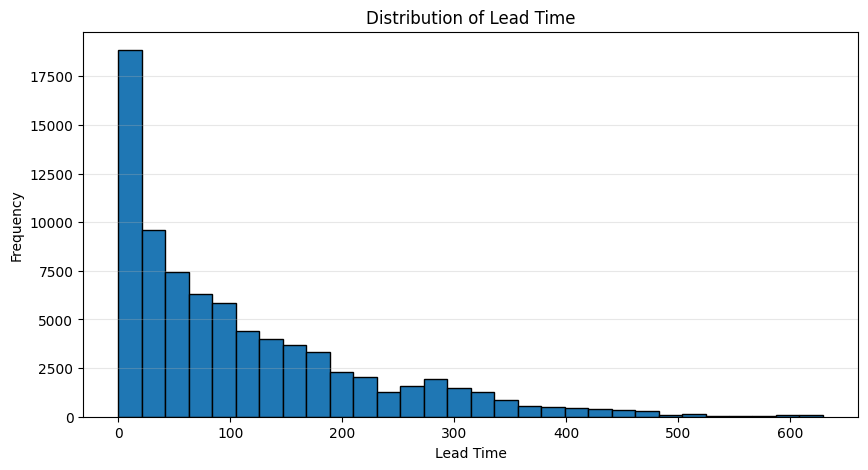

In [94]:
import matplotlib.pyplot as plt
import pandas as pd

# Plot the distribution
plt.figure(figsize=(10, 5))
plt.hist(df['LeadTime'].dropna(), bins=30, edgecolor='black')

plt.title('Distribution of Lead Time')
plt.xlabel('Lead Time')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.3)
plt.show()

In [95]:
Q1 = X_train['LeadTime'].quantile(0.25)
Q3 = X_train['LeadTime'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

print(
    "Training outliers:",
    ((X_train['LeadTime'] < lower_bound) |
     (X_train['LeadTime'] > upper_bound)).sum()
)

print(
    "Testing outliers:",
    ((X_test['LeadTime'] < lower_bound) |
     (X_test['LeadTime'] > upper_bound)).sum()
)

Lower bound: -187.0
Upper bound: 373.0
Training outliers: 2073
Testing outliers: 503


Arrival Dates


In [96]:
month_mapping = {
    'January': 1, 'February': 2, 'March': 3,
    'April': 4, 'May': 5, 'June': 6,
    'July': 7, 'August': 8, 'September': 9,
    'October': 10, 'November': 11, 'December': 12
}

X_train['ArrivalDateMonth'] = X_train['ArrivalDateMonth'].map(month_mapping)
X_test['ArrivalDateMonth'] = X_test['ArrivalDateMonth'].map(month_mapping)

X_train['ArrivalDate'] = pd.to_datetime(
    dict(
        year=X_train['ArrivalDateYear'],
        month=X_train['ArrivalDateMonth'],
        day=X_train['ArrivalDateDayOfMonth']
    ),
    errors='coerce'
)

X_test['ArrivalDate'] = pd.to_datetime(
    dict(
        year=X_test['ArrivalDateYear'],
        month=X_test['ArrivalDateMonth'],
        day=X_test['ArrivalDateDayOfMonth']
    ),
    errors='coerce'
)

X_train['month'] = X_train['ArrivalDate'].dt.month
X_test['month'] = X_test['ArrivalDate'].dt.month

In [97]:
X_train = pd.get_dummies(
    X_train,
    columns=['month'],
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=['month'],
    dtype=int
)

# Ensure both datasets have exactly the same columns
X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

In [98]:
date_columns = [
    'ArrivalDateYear',
    'ArrivalDateMonth',
    'ArrivalDateDayOfMonth',
    'ArrivalDateWeekNumber'
]

X_train.drop(columns=date_columns, inplace=True)
X_test.drop(columns=date_columns, inplace=True)

In [99]:
X_train.head()

,LeadTime,StaysInWeekendNights,StaysInWeekNights,Adults,Children,Babies,Meal,Country,MarketSegment,DistributionChannel,...,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12
12826,71,0,3,1,0.0,0,BB,PRT,Offline TA/TO,TA/TO,...,0,0,0,1,0,0,0,0,0,0
36957,0,0,2,2,0.0,0,BB,PRT,Direct,Direct,...,0,0,0,0,0,1,0,0,0,0
46297,0,0,1,2,1.0,0,BB,PRT,Online TA,TA/TO,...,1,0,0,0,0,0,0,0,0,0
12562,27,0,1,2,0.0,0,BB,PRT,Offline TA/TO,Corporate,...,0,0,0,1,0,0,0,0,0,0
37239,256,1,2,1,0.0,0,BB,ARG,Offline TA/TO,TA/TO,...,0,0,0,0,0,0,1,0,0,0


In [100]:
print(X_train.columns)

Index(['LeadTime', 'StaysInWeekendNights', 'StaysInWeekNights', 'Adults',
       'Children', 'Babies', 'Meal', 'Country', 'MarketSegment',
       'DistributionChannel', 'IsRepeatedGuest', 'PreviousCancellations',
       'PreviousBookingsNotCanceled', 'ReservedRoomType', 'DepositType',
       'Agent', 'Company', 'DaysInWaitingList', 'CustomerType',
       'RequiredCarParkingSpaces', 'TotalOfSpecialRequests', 'ArrivalDate',
       'month_1', 'month_2', 'month_3', 'month_4', 'month_5', 'month_6',
       'month_7', 'month_8', 'month_9', 'month_10', 'month_11', 'month_12'],
      dtype='object')


Nights


In [101]:
X_train['TotalNights'] = (
    X_train['StaysInWeekendNights'] +
    X_train['StaysInWeekNights']
)

X_test['TotalNights'] = (
    X_test['StaysInWeekendNights'] +
    X_test['StaysInWeekNights']
)

X_train['WeekendOrNo'] = (
    X_train['StaysInWeekendNights'] > 0
).astype(int)

X_test['WeekendOrNo'] = (
    X_test['StaysInWeekendNights'] > 0
).astype(int)

In [102]:
zero_nights_train = (X_train["TotalNights"] == 0).sum()
zero_nights_test = (X_test["TotalNights"] == 0).sum()

print(f"Number of bookings with 0 total nights in training set: {zero_nights_train}")
print(f"Number of bookings with 0 total nights in testing set: {zero_nights_test}")

Number of bookings with 0 total nights in training set: 261
Number of bookings with 0 total nights in testing set: 70


In [103]:
# Filter out rows where TotalNights is 0
train_mask = X_train["TotalNights"] > 0
test_mask = X_test["TotalNights"] > 0

X_train = X_train.loc[train_mask].copy()
y_train = y_train.loc[train_mask].copy()

X_test = X_test.loc[test_mask].copy()
y_test = y_test.loc[test_mask].copy()

# Verify
print(f"Remaining training rows: {len(X_train)}")
print(f"Remaining testing rows: {len(X_test)}")

Remaining training rows: 63203
Remaining testing rows: 15796


In [104]:
X_train.drop(
    columns=['StaysInWeekendNights', 'StaysInWeekNights'],
    inplace=True
)
X_test.drop(
    columns=['StaysInWeekendNights', 'StaysInWeekNights'],
    inplace=True
)

Guests


In [105]:
print("Bookings with zero adults:", (df['Adults'] == 0).sum())

Bookings with zero adults: 390


In [106]:
print("Training bookings with zero adults:",
      (X_train['Adults'] == 0).sum())

print("Their ADR values in training:")
print(y_train[X_train['Adults'] == 0].describe())

print("\nTesting bookings with zero adults:",
      (X_test['Adults'] == 0).sum())

print("Their ADR values in testing:")
print(y_test[X_test['Adults'] == 0].describe())

Training bookings with zero adults: 259
Their ADR values in training:
count    259.000000
mean      62.178726
std       47.196595
min        0.000000
25%        6.000000
50%       77.860000
75%       96.825000
max      200.000000
Name: ADR, dtype: float64

Testing bookings with zero adults: 64
Their ADR values in testing:
count     64.000000
mean      60.162344
std       49.244330
min        0.000000
25%        0.000000
50%       79.375000
75%      107.037500
max      131.780000
Name: ADR, dtype: float64


In [107]:
zero_adults = pd.concat([
    X_train[X_train['Adults'] == 0].assign(
        ADR=y_train[X_train['Adults'] == 0]
    ),
    X_test[X_test['Adults'] == 0].assign(
        ADR=y_test[X_test['Adults'] == 0]
    )
])

print(
    zero_adults[
        ['Adults', 'Children', 'Babies', 'ADR']
    ].sort_values('ADR').to_string()
)

       Adults  Children  Babies     ADR
48267       0       0.0       0    0.00
9204        0       0.0       0    0.00
862         0       0.0       0    0.00
36941       0       0.0       0    0.00
15364       0       2.0       0    0.00
62259       0       0.0       0    0.00
53858       0       2.0       0    0.00
56750       0       0.0       0    0.00
1892        0       2.0       0    0.00
69885       0       0.0       0    0.00
54761       0       0.0       0    0.00
70982       0       0.0       0    0.00
29608       0       0.0       0    0.00
53337       0       0.0       0    0.00
36925       0       0.0       0    0.00
332         0       0.0       0    0.00
47957       0       0.0       0    0.00
996         0       0.0       0    0.00
59820       0       0.0       0    0.00
59714       0       0.0       0    0.00
71920       0       0.0       0    0.00
2531        0       0.0       0    0.00
72411       0       0.0       0    0.00
13977       0       0.0       0    0.00


In [108]:
print(
    "Zero adults, children, and babies:",
    (
        (zero_adults['Adults'] == 0) &
        (zero_adults['Children'] == 0) &
        (zero_adults['Babies'] == 0)
    ).sum()
)

Zero adults, children, and babies: 100


In [109]:
print(
    "Zero-adult bookings with ADR = 0:",
    (zero_adults['ADR'] == 0).sum()
)

Zero-adult bookings with ADR = 0: 76


In [110]:
zero_adults = pd.concat([
    X_train.assign(ADR=y_train),
    X_test.assign(ADR=y_test)
])

zero_adults = zero_adults[zero_adults['Adults'] == 0]

no_guests = (
    (zero_adults['Children'] == 0) &
    (zero_adults['Babies'] == 0)
)

zero_adr = zero_adults['ADR'] == 0

print("No guests and ADR = 0:", (no_guests & zero_adr).sum())
print("No guests and ADR > 0:", (no_guests & (zero_adults['ADR'] > 0)).sum())
print("Guests present and ADR = 0:", (~no_guests & zero_adr).sum())
print("Guests present and ADR > 0:", (~no_guests & (zero_adults['ADR'] > 0)).sum())

No guests and ADR = 0: 70
No guests and ADR > 0: 30
Guests present and ADR = 0: 6
Guests present and ADR > 0: 217


In [111]:
# Remove all rows where Adults == 0
train_mask = X_train['Adults'] > 0
test_mask = X_test['Adults'] > 0

X_train = X_train.loc[train_mask].copy()
y_train = y_train.loc[train_mask].copy()

X_test = X_test.loc[test_mask].copy()
y_test = y_test.loc[test_mask].copy()

# Verify
print("Zero-adult rows in training:", (X_train['Adults'] == 0).sum())
print("Zero-adult rows in testing:", (X_test['Adults'] == 0).sum())

print("Remaining training rows:", len(X_train))
print("Remaining testing rows:", len(X_test))

Zero-adult rows in training: 0
Zero-adult rows in testing: 0
Remaining training rows: 62944
Remaining testing rows: 15732


In [112]:
X_train['total_guests'] = (
    X_train['Adults'] + X_train['Children'] + X_train['Babies']
)

X_test['total_guests'] = (
    X_test['Adults'] + X_test['Children'] + X_test['Babies']
)

In [113]:
X_train.drop(columns=['Adults', 'Children', 'Babies'], inplace=True)
X_test.drop(columns=['Adults', 'Children', 'Babies'], inplace=True)

Meal


In [114]:
# Get the count and frequency of each unique value in the Meal column
meal_counts = df["Meal"].value_counts()

print("Meal value counts:")
print(meal_counts)

Meal value counts:
Meal
BB           62305
SC           10564
HB            6417
FB              44
Name: count, dtype: int64


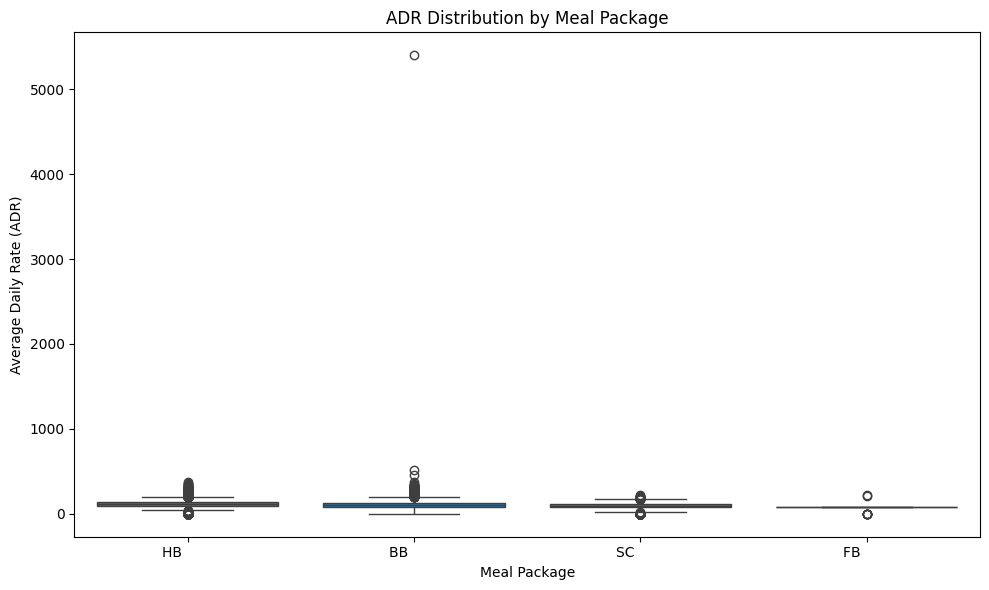

In [115]:
import matplotlib.pyplot as plt

import seaborn as sns

plt.figure(figsize=(10, 6))

sns.boxplot(data=df, x="Meal", y="ADR")

plt.title("ADR Distribution by Meal Package")

plt.xlabel("Meal Package")

plt.ylabel("Average Daily Rate (ADR)")

plt.xticks(rotation=0)

plt.tight_layout()

plt.show()


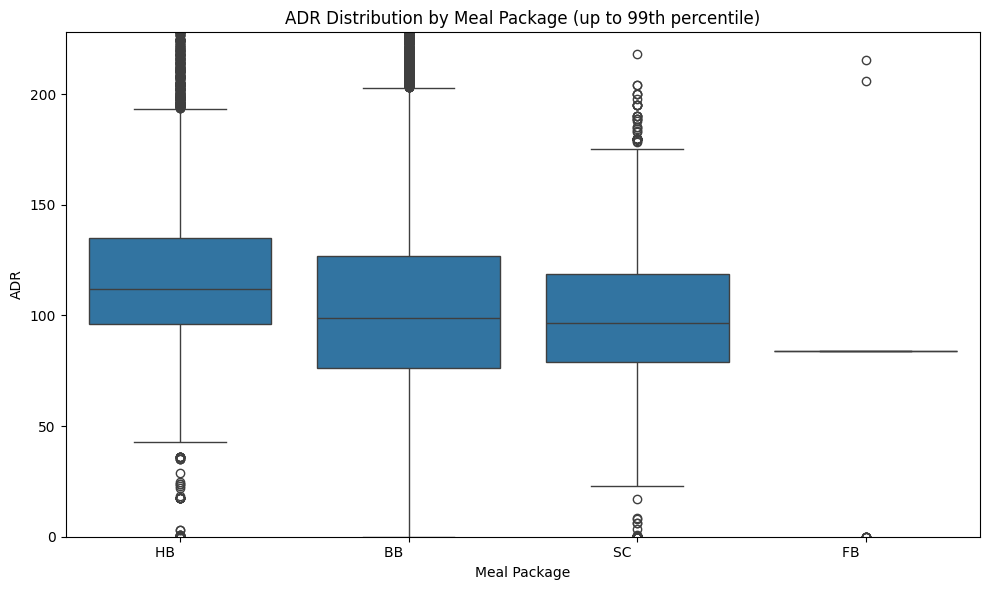

In [116]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the 99th percentile of ADR
upper_limit = df["ADR"].quantile(0.99)

plt.figure(figsize=(10, 6))

sns.boxplot(data=df, x="Meal", y="ADR")

plt.ylim(0, upper_limit)
plt.title("ADR Distribution by Meal Package (up to 99th percentile)")
plt.xlabel("Meal Package")
plt.ylabel("ADR")
plt.tight_layout()
plt.show()

In [117]:
from sklearn.preprocessing import OneHotEncoder
import pandas as pd

# 1. Initialize the encoder
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# 2. Fit on training data and transform both sets
meal_train_array = encoder.fit_transform(X_train[['Meal']])
meal_test_array = encoder.transform(X_test[['Meal']])

# 3. Get the feature names
encoded_feature_names = encoder.get_feature_names_out(['Meal'])

# 4. Convert to DataFrames, preserving indices
meal_train_encoded = pd.DataFrame(
    meal_train_array,
    columns=encoded_feature_names,
    index=X_train.index
)

meal_test_encoded = pd.DataFrame(
    meal_test_array,
    columns=encoded_feature_names,
    index=X_test.index
)

# 5. Concatenate the encoded columns
X_train = pd.concat([X_train, meal_train_encoded], axis=1)
X_test = pd.concat([X_test, meal_test_encoded], axis=1)

# 6. Drop the original categorical column
X_train.drop(columns=['Meal'], inplace=True)
X_test.drop(columns=['Meal'], inplace=True)

print(X_train.head())
print(X_test.head())

       LeadTime Country  MarketSegment DistributionChannel  IsRepeatedGuest  \
12826        71     PRT  Offline TA/TO               TA/TO                0   
36957         0     PRT         Direct              Direct                0   
46297         0     PRT      Online TA               TA/TO                0   
12562        27     PRT  Offline TA/TO           Corporate                0   
37239       256     ARG  Offline TA/TO               TA/TO                0   

       PreviousCancellations  PreviousBookingsNotCanceled  ReservedRoomType  \
12826                      0                            0  A                  
36957                      0                            0  A                  
46297                      0                            0  A                  
12562                      0                            0  A                  
37239                      0                            0  A                  

           DepositType        Agent  ... month_10 

Country


/tmp/ipykernel_2618/3265771084.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


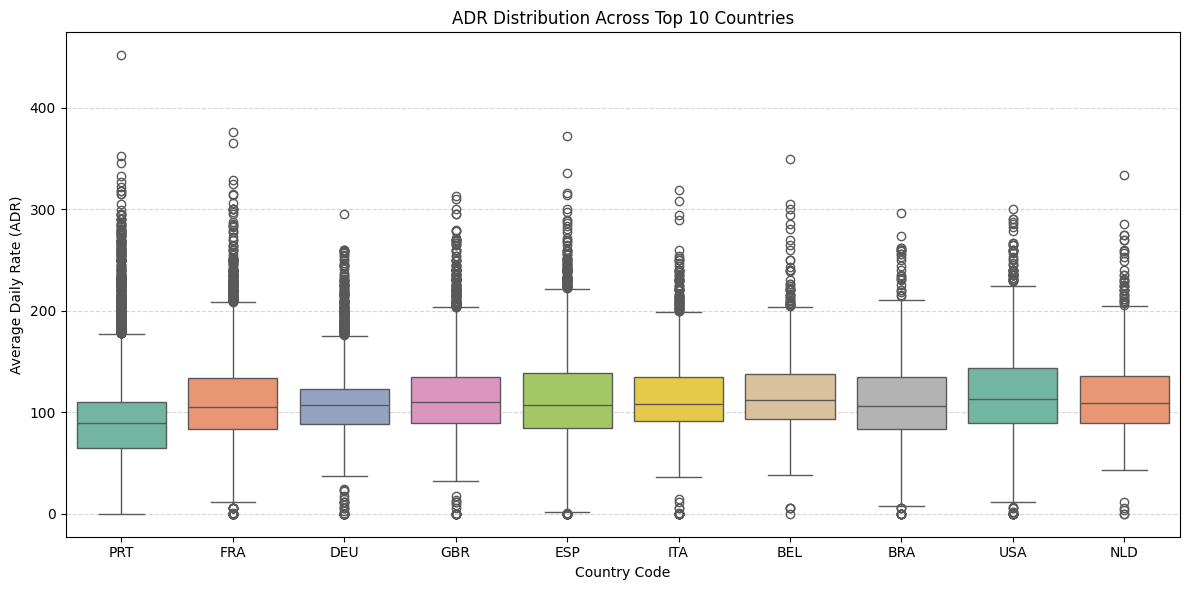

In [118]:
import matplotlib.pyplot as plt
import seaborn as sb
import pandas as pd

# 1. Find the top 10 most frequent countries
top_10_countries = df["Country"].value_counts().head(10).index

# 2. Filter the dataframe to include only these top 10 countries
df_top10 = df[df["Country"].isin(top_10_countries)]

# 3. Create the boxplot
plt.figure(figsize=(12, 6))

# Use ylim or filter out extreme ADR outliers (like the $5,400 anomaly) for better visibility
df_filtered_adr = df_top10[df_top10["ADR"] < 500]

sns.boxplot(
    x="Country", y="ADR", data=df_filtered_adr, order=top_10_countries, palette="Set2"
)

plt.title("ADR Distribution Across Top 10 Countries")
plt.xlabel("Country Code")
plt.ylabel("Average Daily Rate (ADR)")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [119]:
X_train['is_local'] = (X_train['Country'] == 'PRT').astype(int)
X_test['is_local'] = (X_test['Country'] == 'PRT').astype(int)

# Verify the value counts
print("Training set:")
print(X_train['is_local'].value_counts())

print("\nTest set:")
print(X_test['is_local'].value_counts())

Training set:
is_local
0    38525
1    24419
Name: count, dtype: int64

Test set:
is_local
0    9557
1    6175
Name: count, dtype: int64


In [120]:
X_train.drop(columns=['Country'], inplace=True)
X_test.drop(columns=['Country'], inplace=True)

MarketSegment
 & DistributionChannel


In [121]:
segments_counts = df["MarketSegment"].value_counts()

print("segments counts:")
print(segments_counts)

segments counts:
MarketSegment
Online TA        38748
Offline TA/TO    16747
Groups           13975
Direct            6093
Corporate         2986
Complementary      542
Aviation           237
Undefined            2
Name: count, dtype: int64


In [122]:
df.groupby("MarketSegment")["ADR"].agg(

    count="count",

    mean="mean",

    median="median"

).sort_values("count", ascending=False)


,count,mean,median
MarketSegment,,,
Online TA,38748,118.919533,114.00
Offline TA/TO,16747,93.017660,90.00
Groups,13975,84.921885,75.00
Direct,6093,119.479682,111.25
Corporate,2986,83.119980,79.00
Complementary,542,2.600424,0.00
Aviation,237,100.142110,95.00
Undefined,2,15.000000,15.00


In [123]:
# Training set: ADR for Undefined MarketSegment
undefined_train = X_train['MarketSegment'] == 'Undefined'

print("Training set — Undefined MarketSegment:")
print(y_train.loc[undefined_train].describe())
print("Number of rows:", undefined_train.sum())

# Test set: ADR for Undefined MarketSegment
undefined_test = X_test['MarketSegment'] == 'Undefined'

print("\nTest set — Undefined MarketSegment:")
print(y_test.loc[undefined_test].describe())
print("Number of rows:", undefined_test.sum())

Training set — Undefined MarketSegment:
count     2.000000
mean     15.000000
std       4.242641
min      12.000000
25%      13.500000
50%      15.000000
75%      16.500000
max      18.000000
Name: ADR, dtype: float64
Number of rows: 2

Test set — Undefined MarketSegment:
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: ADR, dtype: float64
Number of rows: 0


In [124]:
undefined_train = X_train['MarketSegment'] == 'Undefined'

print(X_train.loc[undefined_train, ['MarketSegment', 'DistributionChannel']])
print("\nDistribution channel counts:")
print(X_train.loc[undefined_train, 'DistributionChannel'].value_counts(dropna=False))

    MarketSegment DistributionChannel
540     Undefined           Undefined
619     Undefined           Undefined

Distribution channel counts:
DistributionChannel
Undefined    2
Name: count, dtype: int64


In [125]:
import pandas as pd

# Combine features and target
train_data = pd.concat([X_train, y_train.rename('ADR')], axis=1)

# Get the two Undefined rows from your original data copy
undefined_rows = train_data[
    (train_data['MarketSegment'] == 'Undefined') &
    (train_data['DistributionChannel'] == 'Undefined')
]

# ADR distribution for each valid MarketSegment
segment_adr = (
    train_data[train_data['MarketSegment'] != 'Undefined']
    .groupby('MarketSegment')['ADR']
    .agg(['count', 'mean', 'median', 'std'])
    .sort_values('median')
)

print("ADR distribution by MarketSegment:")
print(segment_adr)

print("\nADR values of the two Undefined bookings:")
print(undefined_rows[['ADR']])

ADR distribution by MarketSegment:
               count        mean  median        std
MarketSegment                                      
Complementary    399    2.768997     0.0  14.882961
Groups         11074   85.015584    75.0  30.944839
Corporate       2386   83.546027    79.0  23.804882
Offline TA/TO  13384   93.720137    90.0  53.113501
Aviation         183  102.531038    95.0  15.048401
Direct          4739  121.561019   112.5  46.276812
Online TA      30777  119.528884   114.3  37.474407

ADR values of the two Undefined bookings:
      ADR
540  12.0
619  18.0


In [126]:
X_train.drop(index=[540, 619], inplace=True)
y_train.drop(index=[540, 619], inplace=True)

In [127]:
# Define the mapping
segment_mapping = {
    'Complementary': 0,
    'Corporate': 1,
    'Groups': 1,
    'Offline TA/TO': 2,
    'Aviation': 2,
    'Direct': 3,
    'Online TA': 3
}

# Apply mapping to training and test sets
X_train['market_segment_tier'] = X_train['MarketSegment'].map(segment_mapping)
X_test['market_segment_tier'] = X_test['MarketSegment'].map(segment_mapping)

# Check the distributions
print("Training set:")
print(X_train['market_segment_tier'].value_counts(dropna=False).sort_index())

print("\nTest set:")
print(X_test['market_segment_tier'].value_counts(dropna=False).sort_index())

# Drop the original column
X_train.drop(columns=['MarketSegment'], inplace=True)
X_test.drop(columns=['MarketSegment'], inplace=True)

Training set:
market_segment_tier
0      399
1    13460
2    13567
3    35516
Name: count, dtype: int64

Test set:
market_segment_tier
0     111
1    3456
2    3304
3    8861
Name: count, dtype: int64


In [128]:
channel_counts = df["DistributionChannel"].value_counts()

print("DistributionChannel:")
print(channel_counts)

DistributionChannel:
DistributionChannel
TA/TO        68945
Direct        6780
Corporate     3408
GDS            193
Undefined        4
Name: count, dtype: int64


In [129]:
# Compare Market Segment against ADR
market_adr = (
    df.groupby("MarketSegment")["ADR"]
    .agg(count="count", mean="mean", median="median")
    .sort_values("mean", ascending=False)
)

display(market_adr)

# Compare Distribution Channel against ADR
channel_adr = (
    df.groupby("DistributionChannel")["ADR"]
    .agg(count="count", mean="mean", median="median")
    .sort_values("mean", ascending=False)
)

display(channel_adr)

,count,mean,median
MarketSegment,,,
Direct,6093,119.479682,111.25
Online TA,38748,118.919533,114.00
Aviation,237,100.142110,95.00
Offline TA/TO,16747,93.017660,90.00
Groups,13975,84.921885,75.00
Corporate,2986,83.119980,79.00
Undefined,2,15.000000,15.00
Complementary,542,2.600424,0.00


,count,mean,median
DistributionChannel,,,
GDS,193,120.554301,115.0
Direct,6780,110.808417,107.0
TA/TO,68945,105.742511,100.0
Corporate,3408,84.718104,80.0
Undefined,4,29.625000,15.0


In [130]:
pd.crosstab(
    df["MarketSegment"],
    df["DistributionChannel"]
)

DistributionChannel,Corporate,Direct,GDS,TA/TO,Undefined
MarketSegment,,,,,
Aviation,227,0,0,10,0
Complementary,69,437,0,36,0
Corporate,2636,56,0,294,0
Direct,6,6048,1,37,1
Groups,240,177,0,13558,0
Offline TA/TO,198,6,45,16498,0
Online TA,32,56,147,38512,1
Undefined,0,0,0,0,2


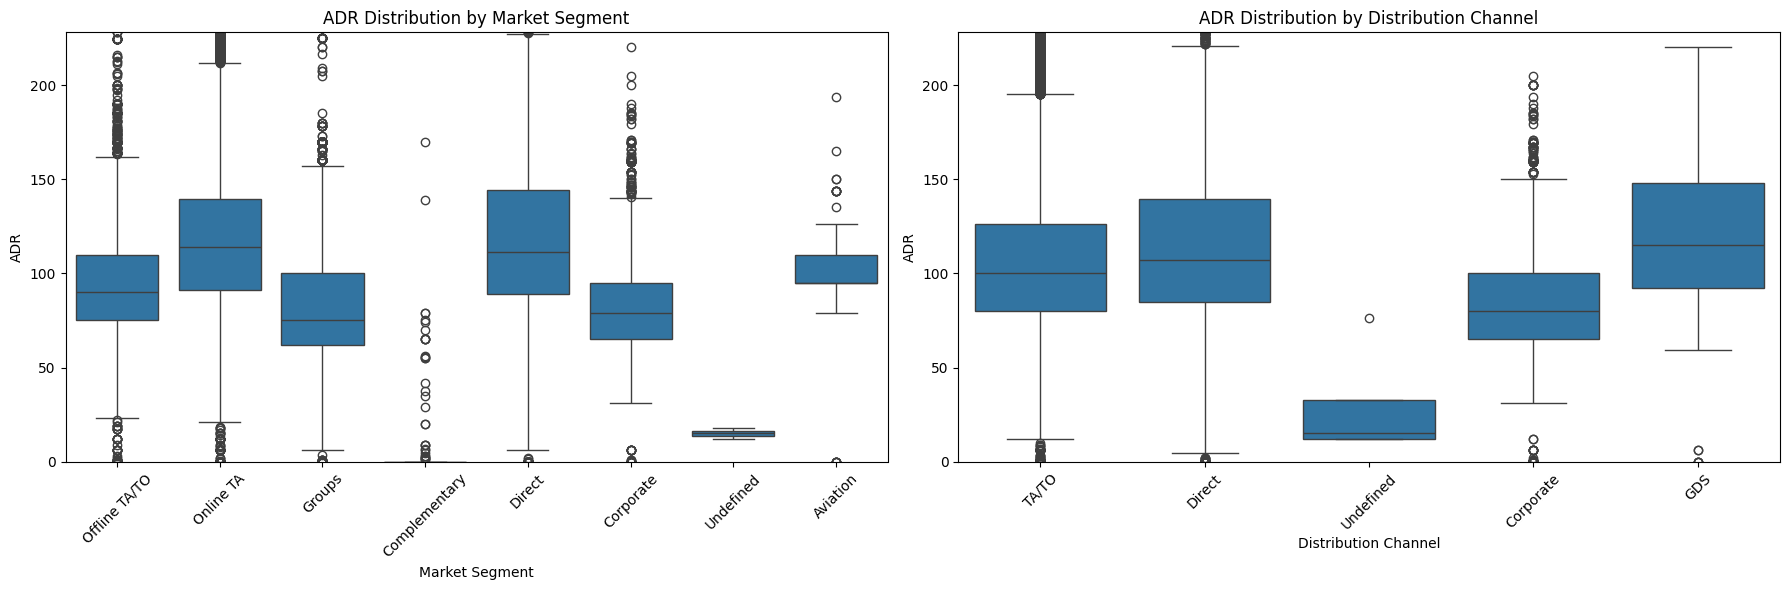

In [131]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create two plots side by side
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Plot 1: Market Segment vs ADR
sns.boxplot(data=df, x="MarketSegment", y="ADR", ax=axes[0])
axes[0].set_title("ADR Distribution by Market Segment")
axes[0].set_xlabel("Market Segment")
axes[0].set_ylabel("ADR")
axes[0].tick_params(axis="x", rotation=45)

# Plot 2: Distribution Channel vs ADR
sns.boxplot(data=df, x="DistributionChannel", y="ADR", ax=axes[1])
axes[1].set_title("ADR Distribution by Distribution Channel")
axes[1].set_xlabel("Distribution Channel")
axes[1].set_ylabel("ADR")
axes[1].tick_params(axis="x", rotation=45)

# Limit both y-axes to the 99th percentile for readability
upper_limit = df["ADR"].quantile(0.99)
axes[0].set_ylim(0, upper_limit)
axes[1].set_ylim(0, upper_limit)

plt.tight_layout()
plt.show()

In [132]:
X_train.drop(columns=['DistributionChannel'], inplace=True)
X_test.drop(columns=['DistributionChannel'], inplace=True)


GuestHistory


In [133]:
print(df["IsRepeatedGuest"].value_counts())

IsRepeatedGuest
0    77298
1     2032
Name: count, dtype: int64


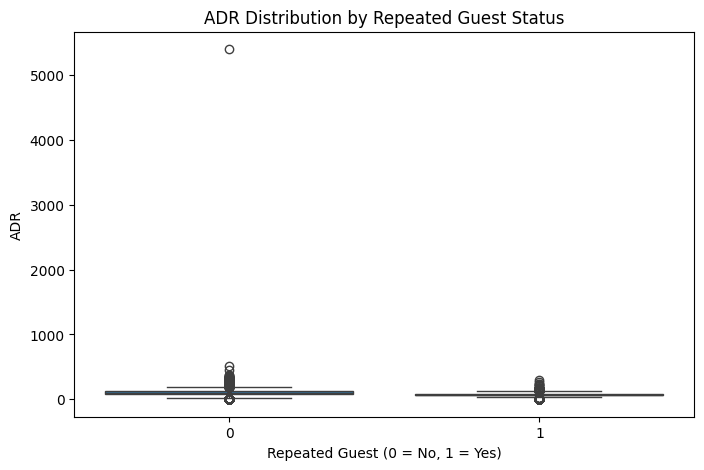

In [134]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="IsRepeatedGuest", y="ADR")

plt.title("ADR Distribution by Repeated Guest Status")
plt.xlabel("Repeated Guest (0 = No, 1 = Yes)")
plt.ylabel("ADR")
plt.show()

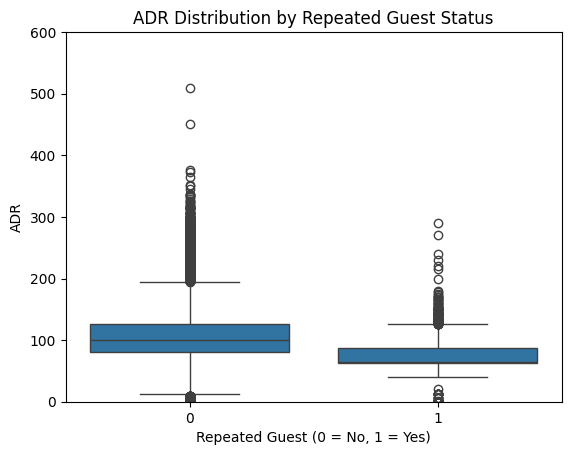

In [135]:
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming your data is in a DataFrame named 'df'
sns.boxplot(x='IsRepeatedGuest', y='ADR', data=df)

# Set the y-axis limits to focus on the bulk of the data (e.g., between 0 and 600)
plt.ylim(0, 600)

plt.xlabel("Repeated Guest (0 = No, 1 = Yes)")
plt.ylabel("ADR")
plt.title("ADR Distribution by Repeated Guest Status")
plt.show()

In [136]:
print(df["PreviousCancellations"].value_counts())

PreviousCancellations
0     73941
1      5155
2        72
3        51
11       35
4        25
6        22
5        16
13       12
21        1
Name: count, dtype: int64


In [137]:
# Create the feature in both datasets
X_train['has_previous_cancellations'] = (
    X_train['PreviousCancellations'] > 0
).astype(int)

X_test['has_previous_cancellations'] = (
    X_test['PreviousCancellations'] > 0
).astype(int)

# Drop the original column
X_train.drop(columns=['PreviousCancellations'], inplace=True)
X_test.drop(columns=['PreviousCancellations'], inplace=True)

In [138]:
print(df["PreviousBookingsNotCanceled"].value_counts())

PreviousBookingsNotCanceled
0     77742
1       569
2       192
3       129
4       102
      ...  
68        1
69        1
70        1
71        1
72        1
Name: count, Length: 73, dtype: int64


In [139]:
X_train['has_previous_bookings_not_canceled'] = (
    X_train['PreviousBookingsNotCanceled'] > 0
).astype(int)

X_test['has_previous_bookings_not_canceled'] = (
    X_test['PreviousBookingsNotCanceled'] > 0
).astype(int)

In [140]:
X_train.drop(columns=['PreviousBookingsNotCanceled'], inplace=True)
X_test.drop(columns=['PreviousBookingsNotCanceled'], inplace=True)

Reserved Room Type


In [141]:
print(df["ReservedRoomType"].value_counts())

ReservedRoomType
A                   62595
D                   11768
F                    1791
E                    1553
B                    1115
G                     484
C                      14
P                      10
Name: count, dtype: int64


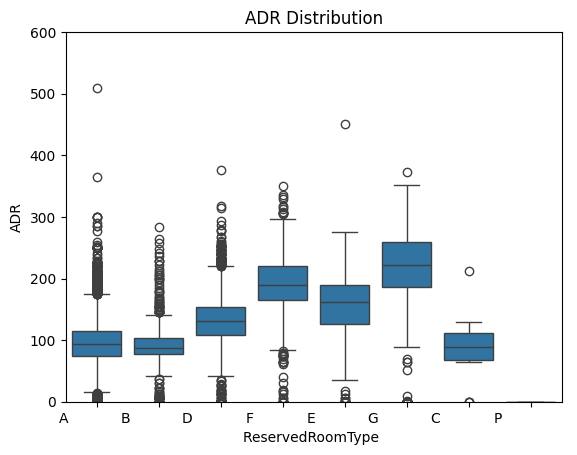

In [142]:
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming your data is in a DataFrame named 'df'
sns.boxplot(x='ReservedRoomType', y='ADR', data=df)

# Set the y-axis limits to focus on the bulk of the data (e.g., between 0 and 600)
plt.ylim(0, 600)

plt.xlabel("ReservedRoomType ")
plt.ylabel("ADR")
plt.title("ADR Distribution")
plt.show()

In [143]:
# Training set
p_train = X_train['ReservedRoomType'] == 'P'

print("Training set — ReservedRoomType = P")
print(y_train.loc[p_train].describe())
print("Number of rows:", p_train.sum())

# Test set
p_test = X_test['ReservedRoomType'] == 'P'

print("\nTest set — ReservedRoomType = P")
print(y_test.loc[p_test].describe())
print("Number of rows:", p_test.sum())

Training set — ReservedRoomType = P
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: ADR, dtype: float64
Number of rows: 0

Test set — ReservedRoomType = P
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: ADR, dtype: float64
Number of rows: 0


In [144]:
print(df["ReservedRoomType"].value_counts())

ReservedRoomType
A                   62595
D                   11768
F                    1791
E                    1553
B                    1115
G                     484
C                      14
P                      10
Name: count, dtype: int64


In [145]:
# Training set
c_train = X_train['ReservedRoomType'] == 'C'

print("Training set — ReservedRoomType = C")
print(y_train.loc[c_train].describe())
print("Number of rows:", c_train.sum())

# Test set
c_test = X_test['ReservedRoomType'] == 'C'

print("\nTest set — ReservedRoomType = C")
print(y_test.loc[c_test].describe())
print("Number of rows:", c_test.sum())

Training set — ReservedRoomType = C
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: ADR, dtype: float64
Number of rows: 0

Test set — ReservedRoomType = C
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: ADR, dtype: float64
Number of rows: 0


Deposit Type


In [146]:
print(df["DepositType"].value_counts())

DepositType
No Deposit         66442
Non Refund         12868
Refundable            20
Name: count, dtype: int64


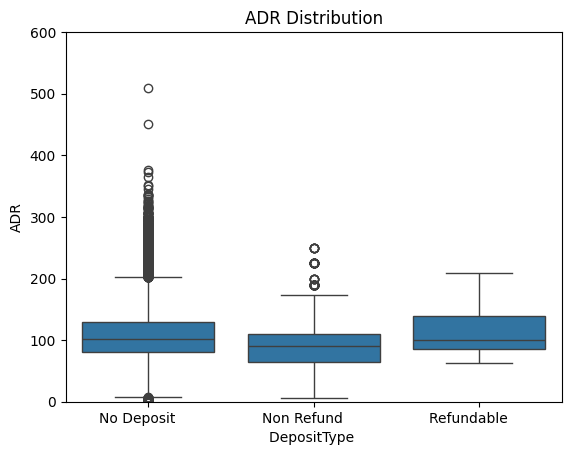

In [147]:
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming your data is in a DataFrame named 'df'
sns.boxplot(x='DepositType', y='ADR', data=df)

# Set the y-axis limits to focus on the bulk of the data (e.g., between 0 and 600)
plt.ylim(0, 600)

plt.xlabel("DepositType ")
plt.ylabel("ADR")
plt.title("ADR Distribution")
plt.show()

In [148]:
# Apply one-hot encoding to DepositType
X_train = pd.get_dummies(
    X_train, columns=['DepositType'], drop_first=True, dtype=int
)

X_test = pd.get_dummies(
    X_test, columns=['DepositType'], drop_first=True, dtype=int
)

# Ensure both datasets have the same columns
X_train, X_test = X_train.align(
    X_test, join='left', axis=1, fill_value=0
)

In [149]:
X_train.head()

,LeadTime,IsRepeatedGuest,ReservedRoomType,Agent,Company,DaysInWaitingList,CustomerType,RequiredCarParkingSpaces,TotalOfSpecialRequests,ArrivalDate,...,Meal_BB,Meal_FB,Meal_HB,Meal_SC,is_local,market_segment_tier,has_previous_cancellations,has_previous_bookings_not_canceled,DepositType_Non Refund,DepositType_Refundable
12826,71,0,A,236,NULL,0,Transient,0,0,2016-06-14,...,1.0,0.0,0.0,0.0,1,2,0,0,1,0
36957,0,0,A,NULL,NULL,0,Transient,0,1,2015-08-28,...,1.0,0.0,0.0,0.0,1,3,0,0,0,0
46297,0,0,A,9,NULL,0,Transient,0,0,2016-03-31,...,1.0,0.0,0.0,0.0,1,3,0,0,0,0
12562,27,0,A,191,NULL,0,Transient-Party,0,0,2016-06-09,...,1.0,0.0,0.0,0.0,1,2,0,0,0,0
37239,256,0,A,4,NULL,0,Transient-Party,0,0,2015-09-14,...,1.0,0.0,0.0,0.0,0,2,0,0,0,0


Agent


In [150]:
agent_counts = df["Agent"].value_counts()

print("Agent value counts:")
print(agent_counts)

Agent value counts:
Agent
   9    31955
NULL     8131
   1     7137
  14     3640
   7     3539
        ...  
 388        1
 453        1
 480        1
 464        1
 476        1
Name: count, Length: 224, dtype: int64


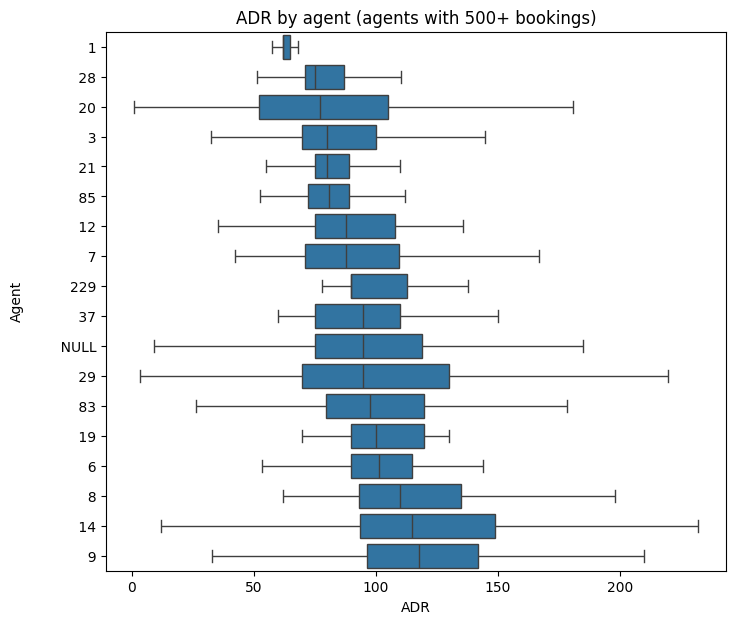

In [151]:
import seaborn as sns
import matplotlib.pyplot as plt

d = df[df.ADR > 0]
top = d.Agent.value_counts()[lambda s: s >= 500].index
sub = d[d.Agent.isin(top)]
order = sub.groupby('Agent').ADR.median().sort_values().index

plt.figure(figsize=(8, 7))
sns.boxplot(data=sub, y='Agent', x='ADR', order=order, showfliers=False)
plt.title('ADR by agent (agents with 500+ bookings)')
plt.show()

In [152]:
!pip install category_encoders

In [153]:
from category_encoders import TargetEncoder

# Initialize the encoder
encoder = TargetEncoder(cols=['Agent'], smoothing=10)

# Fit on training data only, using the target
X_train['Agent'] = encoder.fit_transform(
    X_train[['Agent']], y_train
)['Agent']

# Transform the test data without fitting on it
X_test['Agent'] = encoder.transform(
    X_test[['Agent']]
)['Agent']

In [154]:
X_train.head()

,LeadTime,IsRepeatedGuest,ReservedRoomType,Agent,Company,DaysInWaitingList,CustomerType,RequiredCarParkingSpaces,TotalOfSpecialRequests,ArrivalDate,...,Meal_BB,Meal_FB,Meal_HB,Meal_SC,is_local,market_segment_tier,has_previous_cancellations,has_previous_bookings_not_canceled,DepositType_Non Refund,DepositType_Refundable
12826,71,0,A,116.807512,NULL,0,Transient,0,0,2016-06-14,...,1.0,0.0,0.0,0.0,1,2,0,0,1,0
36957,0,0,A,94.559329,NULL,0,Transient,0,1,2015-08-28,...,1.0,0.0,0.0,0.0,1,3,0,0,0,0
46297,0,0,A,123.151688,NULL,0,Transient,0,0,2016-03-31,...,1.0,0.0,0.0,0.0,1,3,0,0,0,0
12562,27,0,A,115.984465,NULL,0,Transient-Party,0,0,2016-06-09,...,1.0,0.0,0.0,0.0,1,2,0,0,0,0
37239,256,0,A,88.325085,NULL,0,Transient-Party,0,0,2015-09-14,...,1.0,0.0,0.0,0.0,0,2,0,0,0,0


Company


In [155]:
company_counts = df["Company"].value_counts()

print("Company value counts:")
print(company_counts)

Company value counts:
Company
NULL    75641
  40      924
  67      267
  45      250
 153      215
        ...  
 481        1
 494        1
 491        1
 421        1
 497        1
Name: count, Length: 208, dtype: int64


In [156]:
# Create Company_flag in both datasets
X_train['Company_flag'] = X_train['Company'].notna().astype(int)
X_test['Company_flag'] = X_test['Company'].notna().astype(int)

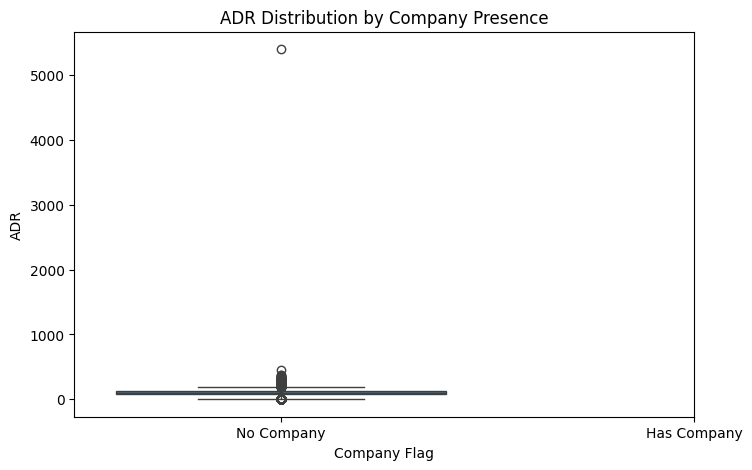

In [157]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Combine the feature and target for visualization
plot_df = X_train[['Company_flag']].copy()
plot_df['ADR'] = y_train

# Box plot
plt.figure(figsize=(8, 5))
sns.boxplot(data=plot_df, x='Company_flag', y='ADR')

plt.xticks([0, 1], ['No Company', 'Has Company'])
plt.title('ADR Distribution by Company Presence')
plt.xlabel('Company Flag')
plt.ylabel('ADR')
plt.show()

In [158]:
X_train.drop(columns=['Company'], inplace=True)
X_test.drop(columns=['Company'], inplace=True)
X_train.drop(columns=['Company_flag'], inplace=True)
X_test.drop(columns=['Company_flag'], inplace=True)

DaysInWaitingList


In [159]:
X_train.drop(columns=['DaysInWaitingList'], inplace=True)
X_test.drop(columns=['DaysInWaitingList'], inplace=True)

Customer Type


In [160]:
# Get the count and frequency of each unique value in the Meal column
cusType_counts = df["CustomerType"].value_counts()

print("Customer Type value counts:")
print(cusType_counts)

Customer Type value counts:
CustomerType
Transient          59404
Transient-Party    17333
Contract            2300
Group                293
Name: count, dtype: int64


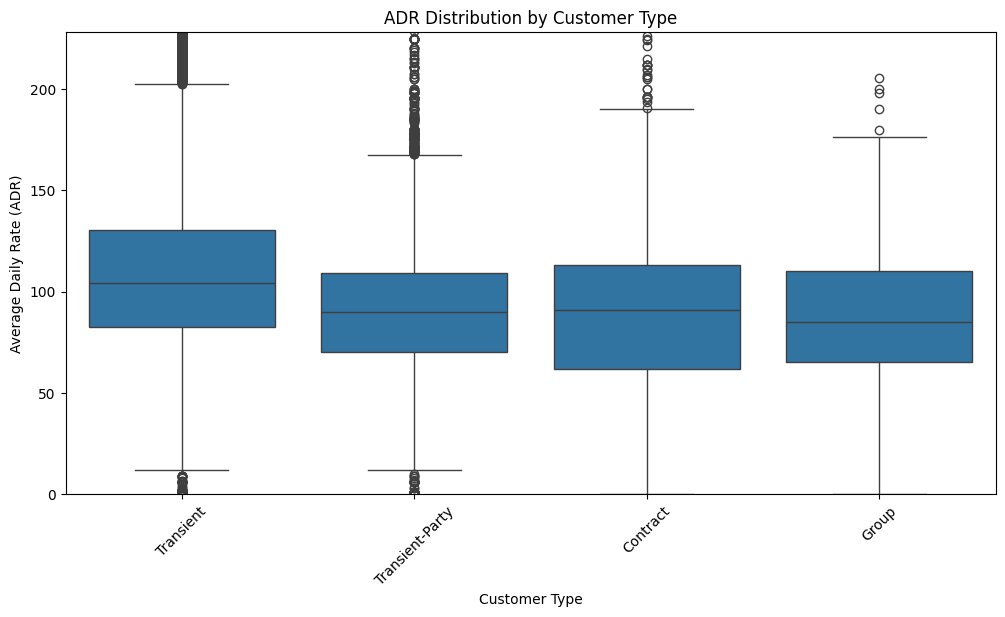

In [161]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.boxplot(data=df, x='CustomerType', y='ADR')

plt.ylim(0, df['ADR'].quantile(0.99))

plt.title('ADR Distribution by Customer Type')
plt.xlabel('Customer Type')
plt.ylabel('Average Daily Rate (ADR)')
plt.xticks(rotation=45)
plt.show()

In [162]:
# Create binary features in both datasets
for data in [X_train, X_test]:
    data['CustomerType_Group'] = (
        data['CustomerType'] == 'Group'
    ).astype(int)

    data['CustomerType_Transient'] = (
        data['CustomerType'] == 'Transient'
    ).astype(int)

    # Drop the original column
    data.drop(columns=['CustomerType'], inplace=True)

CarParking


In [163]:

carcounts = df["RequiredCarParkingSpaces"].value_counts()

print("car value counts:")
print(carcounts)

car value counts:
RequiredCarParkingSpaces
0    77404
1     1921
2        3
3        2
Name: count, dtype: int64


In [164]:
# Create binary feature and drop the original column
for data in [X_train, X_test]:
    data['requirePark'] = (
        data['RequiredCarParkingSpaces'] > 0
    ).astype(int)

    data.drop(columns=['RequiredCarParkingSpaces'], inplace=True)

Special Requests


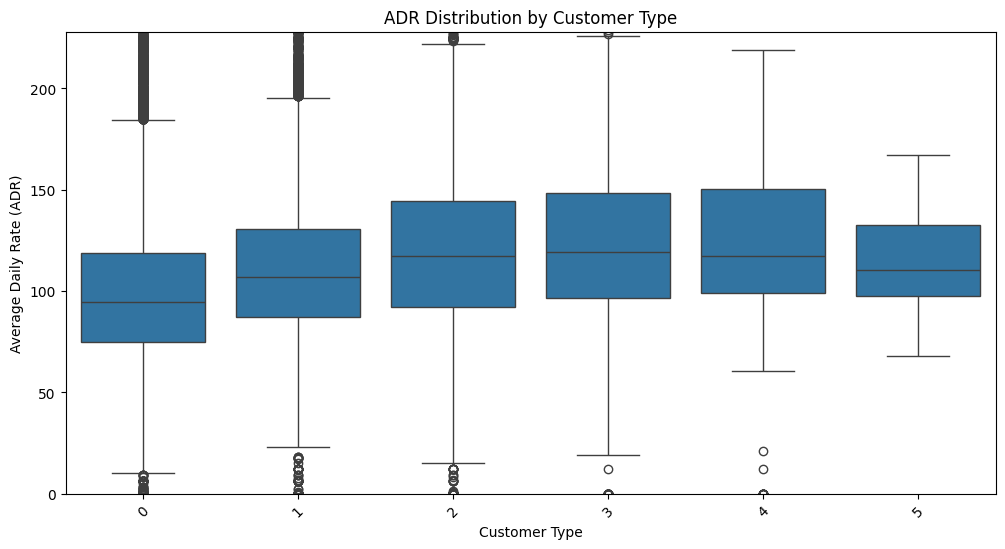

In [165]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.boxplot(data=df, x='TotalOfSpecialRequests', y='ADR')

plt.ylim(0, df['ADR'].quantile(0.99))

plt.title('ADR Distribution by Customer Type')
plt.xlabel('Customer Type')
plt.ylabel('Average Daily Rate (ADR)')
plt.xticks(rotation=45)
plt.show()

In [166]:
# Cap special requests at 3, then drop the original column
for data in [X_train, X_test]:
    data['special_req'] = data['TotalOfSpecialRequests'].clip(upper=3)

    data.drop(columns=['TotalOfSpecialRequests'], inplace=True)

In [167]:
print(df["ReservedRoomType"].value_counts())

ReservedRoomType
A                   62595
D                   11768
F                    1791
E                    1553
B                    1115
G                     484
C                      14
P                      10
Name: count, dtype: int64


In [168]:
print('Total C in original df:', (df['ReservedRoomType'] == 'C').sum())
print('Total P in original df:', (df['ReservedRoomType'] == 'P').sum())

print('\nIs C present in X_train?:', (X_train['ReservedRoomType'] == 'C').sum())
print('Is P present in X_train?:', (X_train['ReservedRoomType'] == 'P').sum())

print('\nIs C present in X_test?:', (X_test['ReservedRoomType'] == 'C').sum())
print('Is P present in X_test?:', (X_test['ReservedRoomType'] == 'P').sum())

# Let's inspect the original C and P rows to see if they had 0 Adults or 0 TotalNights
original_p_c = df[df['ReservedRoomType'].isin(['P', 'C'])]
display(original_p_c[['ReservedRoomType', 'Adults', 'ADR']])

Total C in original df: 0
Total P in original df: 0

Is C present in X_train?: 0
Is P present in X_train?: 0

Is C present in X_test?: 0
Is P present in X_test?: 0


,ReservedRoomType,Adults,ADR


In [169]:
# Let's load the raw data completely fresh without any prior edits or splits
raw_df = pd.read_csv('/content/H2.csv')

# Filter to only 'C' and 'P' rooms
raw_p_c = raw_df[raw_df['ReservedRoomType'].isin(['P', 'C'])]

print(f"Total 'C' rooms in clean file: {len(raw_df[raw_df['ReservedRoomType'] == 'C'])}")
print(f"Total 'P' rooms in clean file: {len(raw_df[raw_df['ReservedRoomType'] == 'P'])}")

# Let's see their actual ADR, Adults, and Total Nights values
print("\nDetailed breakdown of C and P room bookings from raw data:")
display(raw_p_c[['ReservedRoomType', 'Adults', 'Children', 'Babies', 'StaysInWeekendNights', 'StaysInWeekNights', 'ADR']])

Total 'C' rooms in clean file: 0
Total 'P' rooms in clean file: 0

Detailed breakdown of C and P room bookings from raw data:


,ReservedRoomType,Adults,Children,Babies,StaysInWeekendNights,StaysInWeekNights,ADR


In [170]:
print("df:")
print(df['ReservedRoomType'].value_counts(dropna=False))

print("\nX_train:")
print(X_train['ReservedRoomType'].value_counts(dropna=False))

print("\nX_test:")
print(X_test['ReservedRoomType'].value_counts(dropna=False))

df:
ReservedRoomType
A                   62595
D                   11768
F                    1791
E                    1553
B                    1115
G                     484
C                      14
P                      10
Name: count, dtype: int64

X_train:
ReservedRoomType
A                   49835
D                    9329
F                    1472
E                    1202
B                     720
G                     374
C                      10
Name: count, dtype: int64

X_test:
ReservedRoomType
A                   12423
D                    2389
E                     327
F                     309
B                     177
G                     104
C                       3
Name: count, dtype: int64


In [171]:
# Display ADR and key columns for all 10 rows of room type 'P'
room_p_df = df[df['ReservedRoomType'] == 'P']
display(room_p_df[['ReservedRoomType', 'ADR','MarketSegment']])


# Also check summary stats of ADR for room P
print(room_p_df['ADR'].describe())

,ReservedRoomType,ADR,MarketSegment


count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: ADR, dtype: float64


In [172]:
display(
    df.loc[
        df['ReservedRoomType'].isin(['C', 'P']),
        ['ReservedRoomType', 'ADR', 'Adults', 'Children', 'Babies']
    ]
)

,ReservedRoomType,ADR,Adults,Children,Babies


In [173]:
print("P rows in original X:", (X['ReservedRoomType'] == 'P').sum())
print("C rows in original X:", (X['ReservedRoomType'] == 'C').sum())

P rows in original X: 0
C rows in original X: 0


In [174]:
print("df shape:", df.shape)
print("X shape:", X.shape)

print("df and X have the same indices:", df.index.equals(X.index))

print("\nRoom types in df:")
print(df['ReservedRoomType'].value_counts())

print("\nRoom types in X:")
print(X['ReservedRoomType'].value_counts())

df shape: (79330, 26)
X shape: (79330, 25)
df and X have the same indices: True

Room types in df:
ReservedRoomType
A                   62595
D                   11768
F                    1791
E                    1553
B                    1115
G                     484
C                      14
P                      10
Name: count, dtype: int64

Room types in X:
ReservedRoomType
A                   62595
D                   11768
F                    1791
E                    1553
B                    1115
G                     484
C                      14
P                      10
Name: count, dtype: int64


In [175]:
print("P rows in y:", (X.loc[X['ReservedRoomType'] == 'P'].index).size)

print("P rows in X_train:", (X_train['ReservedRoomType'] == 'P').sum())
print("P rows in X_test:", (X_test['ReservedRoomType'] == 'P').sum())

print("\nIndices of P rows in X:")
print(X.index[X['ReservedRoomType'] == 'P'].tolist())

print("\nAre the P indices in either split?")
p_indices = X.index[X['ReservedRoomType'] == 'P']
print("In train:", p_indices.isin(X_train.index).sum())
print("In test:", p_indices.isin(X_test.index).sum())

P rows in y: 0
P rows in X_train: 0
P rows in X_test: 0

Indices of P rows in X:
[]

Are the P indices in either split?
In train: 0
In test: 0


In [176]:
print("CURRENT COUNTS")

for name, data in [
    ("df", df),
    ("X", X),
    ("X_train", X_train),
    ("X_test", X_test)
]:
    print(f"\n{name}:")
    print(
        data["ReservedRoomType"]
        .value_counts(dropna=False)
        .reindex(["C", "P"], fill_value=0)
    )

# Check whether the C and P rows in X are represented in the splits
for room in ["C", "P"]:
    original_indices = X.index[X["ReservedRoomType"] == room]

    print(f"\nRoom type {room}:")
    print("Rows in X:", len(original_indices))
    print("Rows in X_train:", X_train["ReservedRoomType"].eq(room).sum())
    print("Rows in X_test:", X_test["ReservedRoomType"].eq(room).sum())
    print("Original indices in train:", original_indices.isin(X_train.index).sum())
    print("Original indices in test:", original_indices.isin(X_test.index).sum())

CURRENT COUNTS

df:
ReservedRoomType
C    0
P    0
Name: count, dtype: int64

X:
ReservedRoomType
C    0
P    0
Name: count, dtype: int64

X_train:
ReservedRoomType
C    0
P    0
Name: count, dtype: int64

X_test:
ReservedRoomType
C    0
P    0
Name: count, dtype: int64

Room type C:
Rows in X: 0
Rows in X_train: 0
Rows in X_test: 0
Original indices in train: 0
Original indices in test: 0

Room type P:
Rows in X: 0
Rows in X_train: 0
Rows in X_test: 0
Original indices in train: 0
Original indices in test: 0


In [177]:
print("Unique ReservedRoomType values in df:")
print(df['ReservedRoomType'].unique())

print("\nData types:")
print("df:", df['ReservedRoomType'].dtype)
print("X:", X['ReservedRoomType'].dtype)

Unique ReservedRoomType values in df:
['A               ' 'B               ' 'D               '
 'F               ' 'E               ' 'G               '
 'C               ' 'P               ']

Data types:
df: object
X: object


In [178]:
# Remove leading and trailing spaces
df['ReservedRoomType'] = df['ReservedRoomType'].str.strip()
X['ReservedRoomType'] = X['ReservedRoomType'].str.strip()
X_train['ReservedRoomType'] = X_train['ReservedRoomType'].str.strip()
X_test['ReservedRoomType'] = X_test['ReservedRoomType'].str.strip()

In [179]:
print("df:")
print(df['ReservedRoomType'].value_counts())

print("\nX:")
print(X['ReservedRoomType'].value_counts())

print("\nX_train:")
print(X_train['ReservedRoomType'].value_counts())

print("\nX_test:")
print(X_test['ReservedRoomType'].value_counts())

df:
ReservedRoomType
A    62595
D    11768
F     1791
E     1553
B     1115
G      484
C       14
P       10
Name: count, dtype: int64

X:
ReservedRoomType
A    62595
D    11768
F     1791
E     1553
B     1115
G      484
C       14
P       10
Name: count, dtype: int64

X_train:
ReservedRoomType
A    49835
D     9329
F     1472
E     1202
B      720
G      374
C       10
Name: count, dtype: int64

X_test:
ReservedRoomType
A    12423
D     2389
E      327
F      309
B      177
G      104
C        3
Name: count, dtype: int64


In [180]:
room_p_df = df[df['ReservedRoomType'].str.strip() == 'P']

display(room_p_df)

,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,Babies,...,PreviousBookingsNotCanceled,ReservedRoomType,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests
20591,0,2016,November,47,17,4,11,0,0.0,0,...,0,P,No Deposit,NULL,279,0,Transient,0.0,0,0
21184,0,2016,December,50,6,0,0,0,0.0,0,...,0,P,No Deposit,NULL,279,0,Transient,0.0,0,0
21185,0,2016,December,50,6,0,0,0,0.0,0,...,0,P,No Deposit,NULL,279,0,Transient,0.0,0,0
21189,0,2016,December,50,6,0,0,0,0.0,0,...,0,P,No Deposit,NULL,279,0,Transient,0.0,0,0
25847,0,2017,April,15,10,0,0,0,0.0,0,...,0,P,No Deposit,NULL,279,0,Transient,0.0,0,0
25848,0,2017,April,15,10,0,0,0,0.0,0,...,0,P,No Deposit,NULL,279,0,Transient,0.0,0,0
25849,0,2017,April,15,10,0,0,0,0.0,0,...,0,P,No Deposit,NULL,279,0,Transient,0.0,0,0
25850,0,2017,April,15,10,0,0,0,0.0,0,...,0,P,No Deposit,NULL,279,0,Transient,0.0,0,0
32907,0,2017,August,32,11,0,0,0,0.0,0,...,0,P,No Deposit,NULL,NULL,0,Transient,0.0,0,0
32908,0,2017,August,32,11,0,0,0,0.0,0,...,0,P,No Deposit,NULL,NULL,0,Transient,0.0,0,0


In [181]:
# Find the extreme ADR outlier for Room A
room_a_outlier = df[
    (df['ReservedRoomType'].str.strip() == 'A') &
    (df['ADR'] == 5400)
]

# Display the outlier rows
display(room_a_outlier)

print("Number of outlier rows:", len(room_a_outlier))

,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,Babies,...,PreviousBookingsNotCanceled,ReservedRoomType,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests
8455,35,2016,March,13,25,0,1,2,0.0,0,...,0,A,Non Refund,12,NULL,0,Transient,5400.0,0,0


Number of outlier rows: 1


In [182]:
# Calculate IQR for ADR across the entire dataset
Q1 = df['ADR'].quantile(0.25)
Q3 = df['ADR'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

# Find all ADR outliers
adr_outliers = df[
    (df['ADR'] < lower_bound) |
    (df['ADR'] > upper_bound)
].sort_values('ADR', ascending=False)

# Display outliers
display(adr_outliers)

print("Total ADR outliers:", len(adr_outliers))

Q1: 79.2
Q3: 126.0
IQR: 46.8
Lower bound: 9.000000000000014
Upper bound: 196.2


,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,Babies,...,PreviousBookingsNotCanceled,ReservedRoomType,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests
8455,35,2016,March,13,25,0,1,2,0.0,0,...,0,A,Non Refund,12,NULL,0,Transient,5400.00,0,0
71343,0,2017,May,19,9,0,1,1,0.0,0,...,0,A,No Deposit,159,NULL,0,Transient,510.00,0,0
63852,81,2016,December,53,31,1,1,2,2.0,0,...,0,E,No Deposit,NULL,NULL,0,Transient-Party,451.50,0,4
63729,21,2016,December,53,30,0,2,3,0.0,0,...,0,D,No Deposit,9,NULL,0,Transient,375.50,0,0
78455,14,2017,August,33,18,1,2,3,2.0,0,...,0,G,No Deposit,14,NULL,0,Transient,372.33,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
62793,36,2016,December,50,8,0,0,2,0.0,0,...,0,A,No Deposit,85,NULL,0,Transient,0.00,0,0
62838,23,2016,December,50,8,0,0,2,0.0,0,...,0,D,No Deposit,7,NULL,0,Transient,0.00,0,1
63001,22,2016,December,50,8,0,3,1,0.0,0,...,0,A,No Deposit,141,NULL,0,Transient,0.00,0,1
63005,22,2016,December,50,8,0,3,2,0.0,0,...,0,A,No Deposit,141,NULL,0,Transient,0.00,0,2


Total ADR outliers: 3387


In [183]:
# Drop the row where ADR is 5400
df = df[df['ADR'] != 5400].copy()

print("Rows with ADR = 5400 remaining:", (df['ADR'] == 5400).sum())
print("Updated df shape:", df.shape)

Rows with ADR = 5400 remaining: 0
Updated df shape: (79329, 26)


In [184]:
# Clean room type labels
df['ReservedRoomType'] = df['ReservedRoomType'].str.strip()

# Summary statistics by room type
room_adr_summary = (
    df.groupby('ReservedRoomType')['ADR']
    .agg(['count', 'median', 'mean'])
    .round(2)
)

print(room_adr_summary)

                  count  median    mean
ReservedRoomType                       
A                 62594   93.76   96.16
B                  1115   87.00   90.32
C                    14   89.50   85.48
D                 11768  131.78  131.46
E                  1553  161.70  156.80
F                  1791  189.17  189.26
G                   484  221.74  201.80
P                    10    0.00    0.00


In [185]:
# Define the proposed tiers
price_tiers = {
    'Low Tier (A, B, C)': ['A', 'B', 'C'],
    'Mid Tier (D)': ['D'],
    'Upper Tier (E, F)': ['E', 'F'],
    'Luxury Tier (G)': ['G']
}

# Calculate statistics for each tier
for tier_name, room_types in price_tiers.items():
    tier_data = df[df['ReservedRoomType'].isin(room_types)]

    print(f"\n{tier_name}")
    print("Room types:", room_types)
    print("Total bookings:", len(tier_data))
    print("Median ADR:", round(tier_data['ADR'].median(), 2))
    print("Mean ADR:", round(tier_data['ADR'].mean(), 2))


Low Tier (A, B, C)
Room types: ['A', 'B', 'C']
Total bookings: 63723
Median ADR: 93.6
Mean ADR: 96.06

Mid Tier (D)
Room types: ['D']
Total bookings: 11768
Median ADR: 131.78
Mean ADR: 131.46

Upper Tier (E, F)
Room types: ['E', 'F']
Total bookings: 3344
Median ADR: 177.3
Mean ADR: 174.18

Luxury Tier (G)
Room types: ['G']
Total bookings: 484
Median ADR: 221.75
Mean ADR: 201.8


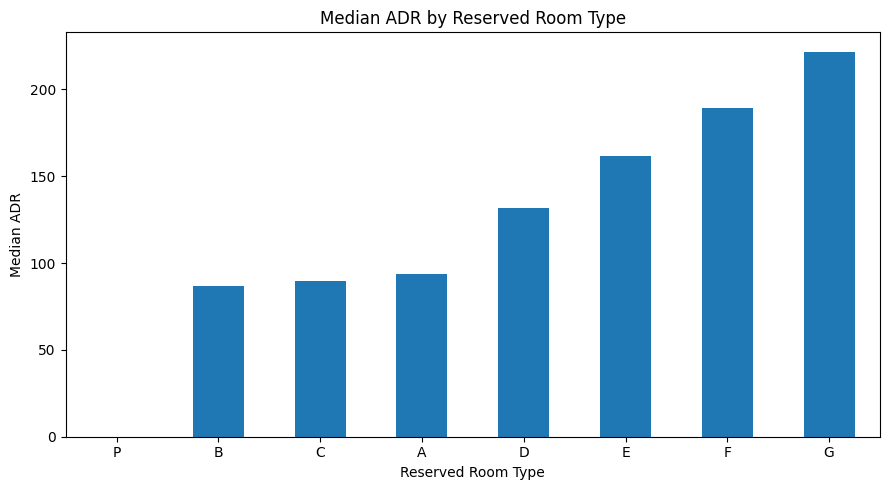

In [186]:
import matplotlib.pyplot as plt

room_medians = df.groupby('ReservedRoomType')['ADR'].median().sort_values()

room_medians.plot(kind='bar', figsize=(9, 5))
plt.title('Median ADR by Reserved Room Type')
plt.xlabel('Reserved Room Type')
plt.ylabel('Median ADR')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [187]:
# Clean room type labels
df['ReservedRoomType'] = df['ReservedRoomType'].str.strip()

# Define price tiers
price_tiers = {
    'Low Tier (A, B, C)': ['A', 'B', 'C'],
    'Mid Tier (D)': ['D'],
    'Upper Tier (E, F)': ['E', 'F'],
    'Luxury Tier (G)': ['G']
}

# Display statistics for each tier
for tier_name, room_types in price_tiers.items():
    tier_data = df[df['ReservedRoomType'].isin(room_types)]

    print(f"\n{tier_name}")
    print("Room types:", room_types)
    print("Number of bookings:", len(tier_data))
    print("Median ADR:", round(tier_data['ADR'].median(), 2))
    print("Mean ADR:", round(tier_data['ADR'].mean(), 2))

# Individual room type statistics
print("\nADR statistics by individual room type:")
print(
    df.groupby('ReservedRoomType')['ADR']
    .agg(['count', 'median', 'mean'])
    .round(2)
)


Low Tier (A, B, C)
Room types: ['A', 'B', 'C']
Number of bookings: 63723
Median ADR: 93.6
Mean ADR: 96.06

Mid Tier (D)
Room types: ['D']
Number of bookings: 11768
Median ADR: 131.78
Mean ADR: 131.46

Upper Tier (E, F)
Room types: ['E', 'F']
Number of bookings: 3344
Median ADR: 177.3
Mean ADR: 174.18

Luxury Tier (G)
Room types: ['G']
Number of bookings: 484
Median ADR: 221.75
Mean ADR: 201.8

ADR statistics by individual room type:
                  count  median    mean
ReservedRoomType                       
A                 62594   93.76   96.16
B                  1115   87.00   90.32
C                    14   89.50   85.48
D                 11768  131.78  131.46
E                  1553  161.70  156.80
F                  1791  189.17  189.26
G                   484  221.74  201.80
P                    10    0.00    0.00


In [188]:
X_train.head()

,LeadTime,IsRepeatedGuest,ReservedRoomType,Agent,ArrivalDate,month_1,month_2,month_3,month_4,month_5,...,is_local,market_segment_tier,has_previous_cancellations,has_previous_bookings_not_canceled,DepositType_Non Refund,DepositType_Refundable,CustomerType_Group,CustomerType_Transient,requirePark,special_req
12826,71,0,A,116.807512,2016-06-14,0,0,0,0,0,...,1,2,0,0,1,0,0,1,0,0
36957,0,0,A,94.559329,2015-08-28,0,0,0,0,0,...,1,3,0,0,0,0,0,1,0,1
46297,0,0,A,123.151688,2016-03-31,0,0,1,0,0,...,1,3,0,0,0,0,0,1,0,0
12562,27,0,A,115.984465,2016-06-09,0,0,0,0,0,...,1,2,0,0,0,0,0,0,0,0
37239,256,0,A,88.325085,2015-09-14,0,0,0,0,0,...,0,2,0,0,0,0,0,0,0,0


In [189]:
room_tier_mapping = {
    'A': 0, 'B': 0, 'C': 0,  # Low tier
    'D': 1,                   # Mid tier
    'E': 2, 'F': 2,          # Upper tier
    'G': 3                    # Luxury tier
}

X_train['ReservedRoomType'] = (
    X_train['ReservedRoomType'].str.strip().map(room_tier_mapping)
)

X_test['ReservedRoomType'] = (
    X_test['ReservedRoomType'].str.strip().map(room_tier_mapping)
)

In [190]:
X_train.head()

,LeadTime,IsRepeatedGuest,ReservedRoomType,Agent,ArrivalDate,month_1,month_2,month_3,month_4,month_5,...,is_local,market_segment_tier,has_previous_cancellations,has_previous_bookings_not_canceled,DepositType_Non Refund,DepositType_Refundable,CustomerType_Group,CustomerType_Transient,requirePark,special_req
12826,71,0,0,116.807512,2016-06-14,0,0,0,0,0,...,1,2,0,0,1,0,0,1,0,0
36957,0,0,0,94.559329,2015-08-28,0,0,0,0,0,...,1,3,0,0,0,0,0,1,0,1
46297,0,0,0,123.151688,2016-03-31,0,0,1,0,0,...,1,3,0,0,0,0,0,1,0,0
12562,27,0,0,115.984465,2016-06-09,0,0,0,0,0,...,1,2,0,0,0,0,0,0,0,0
37239,256,0,0,88.325085,2015-09-14,0,0,0,0,0,...,0,2,0,0,0,0,0,0,0,0


In [191]:
import pandas as pd
from google.colab import files

# Combine the processed training and testing data
X_processed = pd.concat([X_train, X_test]).sort_index()
y_processed = pd.concat([y_train, y_test]).sort_index()

# Add the target column
processed_df = X_processed.copy()
processed_df['ADR'] = y_processed

# Save and download
processed_df.to_csv('processed_hotel_bookingsForRegression.csv', index=False)
files.download('processed_hotel_bookingsForRegression.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [193]:
# Count missing values in each column
print(X_train.isnull().sum()[X_train.isnull().sum() > 0])

# Show the rows containing missing values
missing_rows = X_train[X_train.isnull().any(axis=1)]
display(missing_rows)

# Show the exact column names and row indices
print("Missing value locations:")
print(X_train.isnull().stack()[lambda x: x].index.tolist())

total_guests    2
dtype: int64


,LeadTime,IsRepeatedGuest,ReservedRoomType,Agent,ArrivalDate,month_1,month_2,month_3,month_4,month_5,...,is_local,market_segment_tier,has_previous_cancellations,has_previous_bookings_not_canceled,DepositType_Non Refund,DepositType_Refundable,CustomerType_Group,CustomerType_Transient,requirePark,special_req
1100,8,0,0,123.151688,2015-08-13,0,0,0,0,0,...,1,3,0,0,0,0,0,0,0,1
607,1,0,0,126.523632,2015-08-05,0,0,0,0,0,...,1,3,0,0,0,0,0,0,0,1


Missing value locations:
[(1100, 'total_guests'), (607, 'total_guests')]


In [194]:
# Check the rows with missing total_guests
print(X_train.loc[[1100, 607],
                  ['total_guests']])

# Check the original guest columns in your current dataset
print(df.loc[[1100, 607],
             ['Adults', 'Children', 'Babies']])

      total_guests
1100           NaN
607            NaN
      Adults  Children  Babies
1100       2       NaN       0
607        2       NaN       0


In [195]:
df.loc[[1100, 607], ['Adults', 'Children', 'Babies', 'ADR']]

,Adults,Children,Babies,ADR
1100,2,NaN,0,76.5
607,2,NaN,0,12.0


In [197]:
X_train.loc[[1100, 607], 'total_guests'] = 2

In [198]:
# Count missing values in each column
print(X_train.isnull().sum()[X_train.isnull().sum() > 0])

# Show the rows containing missing values
missing_rows = X_train[X_train.isnull().any(axis=1)]
display(missing_rows)

# Show the exact column names and row indices
print("Missing value locations:")
print(X_train.isnull().stack()[lambda x: x].index.tolist())

Series([], dtype: int64)


,LeadTime,IsRepeatedGuest,ReservedRoomType,Agent,ArrivalDate,month_1,month_2,month_3,month_4,month_5,...,is_local,market_segment_tier,has_previous_cancellations,has_previous_bookings_not_canceled,DepositType_Non Refund,DepositType_Refundable,CustomerType_Group,CustomerType_Transient,requirePark,special_req


Missing value locations:
[]


In [200]:
import pandas as pd
from google.colab import files

# Combine the processed training and testing data
X_processed = pd.concat([X_train, X_test]).sort_index()
y_processed = pd.concat([y_train, y_test]).sort_index()

# Add the target column
processed_df = X_processed.copy()
processed_df['ADR'] = y_processed

# Save and download
processed_df.to_csv('processed_hotel_NEW.csv', index=False)
files.download('processed_hotel_NEW.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>